# AlexNet — ImageNet Classification with Deep Convolutional Neural Networks

**Citation:** Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). ImageNet classification with deep convolutional neural networks. *Advances in Neural Information Processing Systems (NeurIPS)*, 25, 1097–1105.

**Registered names:** `alexnet`

**Summary:** AlexNet won ILSVRC 2012 by a 10.9% margin, demonstrating that deep CNNs trained with ReLU activations, dropout regularisation, and data augmentation could dramatically outperform hand-crafted features. It ignited the deep learning revolution in computer vision.

---

| Property | Value |
|----------|-------|
| Parameters | ~61M |
| embed_dim | 4096 |
| feature_dims | [64, 192, 384, 256, 256] |
| Top-1 (ImageNet) | 56.5% |
| Year | 2012 |

> 📄 **Paper:** Krizhevsky, Sutskever & Hinton (2012). ImageNet Classification with Deep Convolutional Neural Networks. NeurIPS 2012.
> 🔗 **Link:** <https://papers.nips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/alexnet.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> S0["conv 11×11 /4, 64 · ReLU · maxpool 3/2<br/>(B, 64, 27, 27)"]:::stage
  S0 --> S1["conv 5×5, 192 · ReLU · maxpool<br/>(B, 192, 13, 13)"]:::stage
  S1 --> S2["conv 3×3, 384 · ReLU"]:::stage --> S3["conv 3×3, 256 · ReLU"]:::stage
  S3 --> S4["conv 3×3, 256 · ReLU · maxpool<br/>(B, 256, 6, 6)"]:::stage
  S4 --> P["AdaptiveAvgPool 6×6 → flatten 9216"]:::block
  P --> FC["Dropout · FC 4096 · ReLU · Dropout · FC 4096 · ReLU"]:::block --> OUT
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Diagram

```
Input [B, 3, H, W]
       │
       ▼
┌──────────────────────────────────────────────┐
│ Stage 0  Conv(11×11, s4) + ReLU + MaxPool    │ → [B, 64,  H/8,  W/8]
└──────────────────────────────────────────────┘
       │
       ▼
┌──────────────────────────────────────────────┐
│ Stage 1  Conv(5×5, pad2) + ReLU + MaxPool    │ → [B, 192, H/16, W/16]
└──────────────────────────────────────────────┘
       │
       ▼
┌──────────────────────────────────────────────┐
│ Stage 2  Conv(3×3, pad1) + ReLU             │ → [B, 384, H/16, W/16]
└──────────────────────────────────────────────┘
       │
       ▼
┌──────────────────────────────────────────────┐
│ Stage 3  Conv(3×3, pad1) + ReLU             │ → [B, 256, H/16, W/16]
└──────────────────────────────────────────────┘
       │
       ▼
┌──────────────────────────────────────────────┐
│ Stage 4  Conv(3×3, pad1) + ReLU + MaxPool    │ → [B, 256, H/32, W/32]
└──────────────────────────────────────────────┘
       │
       ▼
┌──────────────────────────────────────────────┐
│ AdaptiveAvgPool(6×6) → Flatten               │ → [B, 9216]
│ Dropout → FC(4096) → ReLU                   │
│ Dropout → FC(4096) → ReLU                   │
└──────────────────────────────────────────────┘
       │
       ▼
pooled_output [B, 4096]
```

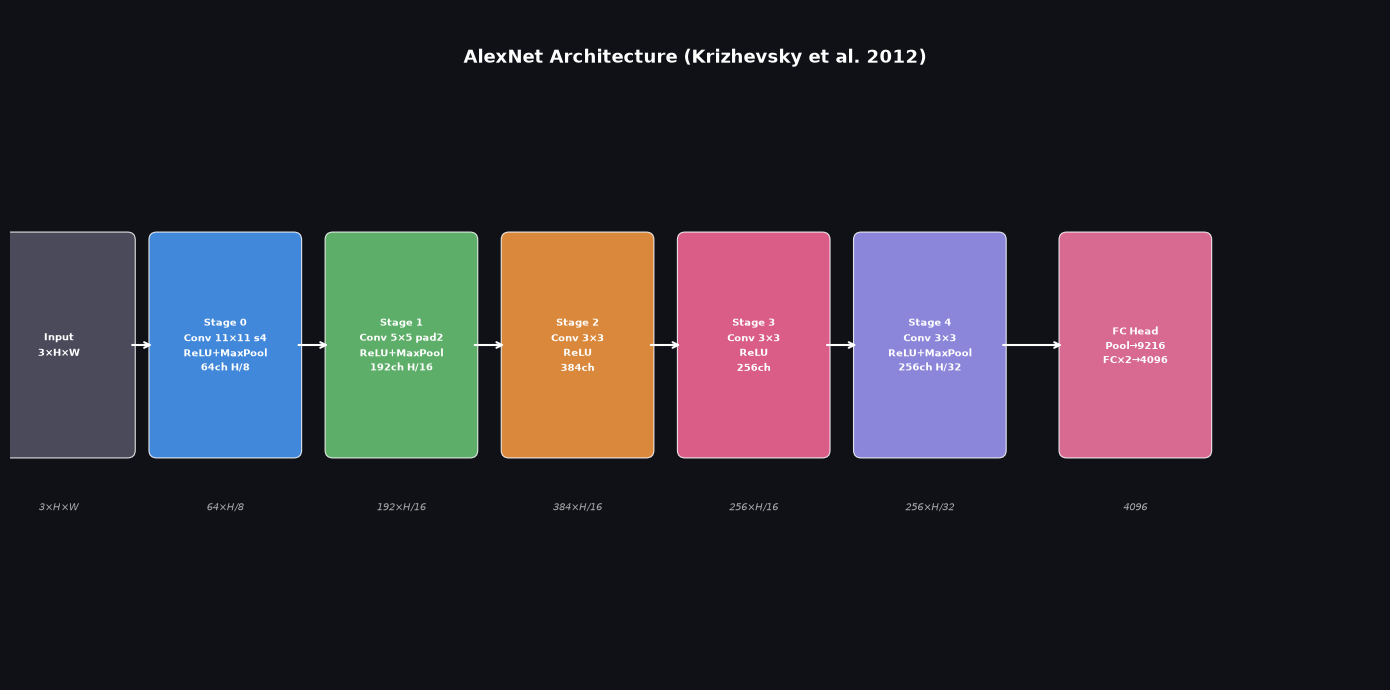

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import numpy as np

fig, ax = plt.subplots(figsize=(14, 7))
fig.patch.set_facecolor('#0f1117')
ax.set_facecolor('#0f1117')
ax.set_xlim(0, 14)
ax.set_ylim(0, 7)
ax.axis('off')

colors = ['#4a9eff', '#6bcb77', '#ff9f43', '#ff6b9d', '#a29bfe', '#fd79a8']
stages = [
    ('Input\n3×H×W', '#555566', 0.5, 3.5),
    ('Stage 0\nConv 11×11 s4\nReLU+MaxPool\n64ch H/8', colors[0], 2.2, 3.5),
    ('Stage 1\nConv 5×5 pad2\nReLU+MaxPool\n192ch H/16', colors[1], 4.0, 3.5),
    ('Stage 2\nConv 3×3\nReLU\n384ch', colors[2], 5.8, 3.5),
    ('Stage 3\nConv 3×3\nReLU\n256ch', colors[3], 7.6, 3.5),
    ('Stage 4\nConv 3×3\nReLU+MaxPool\n256ch H/32', colors[4], 9.4, 3.5),
    ('FC Head\nPool→9216\nFC×2→4096', colors[5], 11.5, 3.5),
]

for label, color, cx, cy in stages:
    box = FancyBboxPatch((cx - 0.7, cy - 1.1), 1.4, 2.2,
                          boxstyle='round,pad=0.08', facecolor=color,
                          edgecolor='white', linewidth=0.8, alpha=0.85)
    ax.add_patch(box)
    ax.text(cx, cy, label, ha='center', va='center', fontsize=7.5,
            color='white', fontweight='bold', linespacing=1.4)

# Arrows between stages
xs = [stage[2] for stage in stages]
for i in range(len(xs) - 1):
    ax.annotate('', xy=(xs[i+1] - 0.72, 3.5), xytext=(xs[i] + 0.72, 3.5),
                arrowprops=dict(arrowstyle='->', color='white', lw=1.5))

# Feature map size annotations below
sizes = ['3×H×W', '64×H/8', '192×H/16', '384×H/16', '256×H/16', '256×H/32', '4096']
for i, (size, (_, _, cx, _)) in enumerate(zip(sizes, stages)):
    ax.text(cx, 1.8, size, ha='center', va='center', fontsize=7,
            color='#aaaaaa', style='italic')

ax.text(7, 6.5, 'AlexNet Architecture (Krizhevsky et al. 2012)',
        ha='center', va='center', fontsize=13, color='white', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### 1. ReLU Activations
AlexNet used **ReLU** (Rectified Linear Unit) instead of sigmoid/tanh:
$$f(x) = \max(0, x)$$
ReLU trains ~6× faster on CIFAR-10 than tanh because it doesn't saturate for large positive activations, avoiding the vanishing gradient problem.

### 2. Dropout Regularisation
Applied after each FC layer with $p = 0.5$:
$$\tilde{h} = h \odot \text{Bernoulli}(1-p)$$
Forces the network to learn redundant representations; interpretable as training an ensemble of $2^N$ thinned networks.

### 3. GPU Training (Dual GTX 580)
The original paper split the model across two GPUs due to 3 GB memory constraints. Modern reimplementations run on a single GPU.

### 4. Local Response Normalisation (LRN)
Originally used between conv stages (inspired by lateral inhibition in neuroscience). Modern implementations replace this with BatchNorm.

### 5. Data Augmentation
Random crops + horizontal flips + colour jitter — now standard practice.

### Historical Significance
AlexNet reduced the ILSVRC 2012 top-5 error from 26.2% (prior winner) to **15.3%**, a margin so large it convinced the research community that deep learning was the path forward.

## Code Walkthrough

The backbone is implemented in `hale_core/nn/vision/cnn/alexnet.py` as `AlexNet(BaseVisionBackbone)`.

**Stage construction:**
```python
self.stage0 = nn.Sequential(
    nn.Conv2d(in_chans, 64, kernel_size=11, stride=4, padding=2),
    nn.ReLU(inplace=True),
    nn.MaxPool2d(kernel_size=3, stride=2),
)
```
The large 11×11 kernel was needed in 2012 to capture texture at coarse scale. Modern designs use 3×3 stacks instead.

**AdaptiveAvgPool** normalises spatial size to 6×6 before the FC layers, making the backbone input-resolution-agnostic:
```python
self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
```

**Weight init:** Kaiming normal for conv (correct variance under ReLU), trunc_normal(std=0.01) for FC layers (matches original paper).

**BackboneOutput:** Returns 5 feature maps (one per stage) + 4096-dim pooled embedding from FC layers.

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/alexnet.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/alexnet.py</code></summary>

```text
AlexNet Vision Backbone
=======================

Implements AlexNet (Krizhevsky, Sutskever & Hinton, NeurIPS 2012).
The first deep CNN to win ImageNet by a large margin, kickstarting the deep
learning revolution in computer vision.

Architecture
------------
Five convolutional stages followed by three fully-connected layers:

  Stage 0: Conv(3→64, 11×11, s4) + ReLU + MaxPool(3,s2)    → H/8
  Stage 1: Conv(64→192, 5×5, pad2) + ReLU + MaxPool(3,s2)  → H/16
  Stage 2: Conv(192→384, 3×3, pad1) + ReLU                 → H/16
  Stage 3: Conv(384→256, 3×3, pad1) + ReLU                 → H/16
  Stage 4: Conv(256→256, 3×3, pad1) + ReLU + MaxPool(3,s2) → H/32
  Classifier: AdaptiveAvgPool → Flatten → FC(4096) → FC(4096)

The AdaptiveAvgPool normalises spatial size before the FC classifier,
making the backbone work on any input resolution (original assumed 227×227).

Weight initialisation:
  Convolutions: Kaiming normal.
  Linear layers: truncated normal (std=0.01) — original used normal(0, 0.01).

Registered names
----------------
  alexnet — embed_dim=4096

Citation
--------
  Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). ImageNet Classification
  with Deep Convolutional Neural Networks. NeurIPS, 25, 1097–1105.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/alexnet.py`, definition by definition

**`AlexNet`** - AlexNet backbone adapted for dense feature extraction.

In [5]:
class AlexNet(BaseVisionBackbone):
    """AlexNet backbone adapted for dense feature extraction.

    Returns 5 stage feature maps (from each conv block) plus a 4096-dim
    pooled embedding from the FC layers.

    Args:
        img_size:  Expected input spatial resolution (any size works due to AdaptiveAvgPool).
        in_chans:  Input channels (default 3).
        drop_rate: Dropout probability in the FC classifier.
    """

    arch_name    = "alexnet"
    embed_dim    = 4096
    feature_dims = [64, 192, 384, 256, 256]

    def __init__(
        self,
        img_size:  int   = 224,
        in_chans:  int   = 3,
        drop_rate: float = 0.5,
        **kwargs,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate)

        # Stage 0: large 11×11 receptive field at stride 4 to aggressively downsample
        # Original AlexNet used stride=4 on 227×227 input; AdaptiveAvgPool handles any size
        self.stage0 = nn.Sequential(
            nn.Conv2d(in_chans, 64, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )

        # Stage 1: 5×5 conv to capture mid-level texture
        self.stage1 = nn.Sequential(
            nn.Conv2d(64, 192, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )

        # Stages 2–4: stack of 3×3 convs for fine-grained features
        self.stage2 = nn.Sequential(
            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.stage3 = nn.Sequential(
            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.stage4 = nn.Sequential(
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )

        # Adaptive pool normalises varying input sizes to 6×6 before the FC classifier
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))

        p = drop_rate if drop_rate > 0.0 else 0.0
        self.classifier = nn.Sequential(
            nn.Dropout(p=p),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=p),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
        )

        self._stages = [self.stage0, self.stage1, self.stage2, self.stage3, self.stage4]
        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                # Original paper: normal(0, 0.01); trunc_normal avoids rare large inits
                nn.init.trunc_normal_(m.weight, std=0.01)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        s0 = self.stage0(x)   # [B, 64,  H/8,  W/8]
        s1 = self.stage1(s0)  # [B, 192, H/16, W/16]
        s2 = self.stage2(s1)  # [B, 384, H/16, W/16]
        s3 = self.stage3(s2)  # [B, 256, H/16, W/16]
        s4 = self.stage4(s3)  # [B, 256, H/32, W/32]

        pooled = self.avgpool(s4)               # [B, 256, 6, 6]
        pooled = pooled.flatten(1)              # [B, 9216]
        pooled = self.classifier(pooled)        # [B, 4096]

        all_maps = [s0, s1, s2, s3, s4]
        if self.out_indices is not None:
            all_maps = [all_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=all_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        if stage < 0 or stage > 4:
            raise ValueError(f"stage must be in [0, 4], got {stage}")
        for i in range(stage + 1):
            for p in self._stages[i].parameters():
                p.requires_grad_(False)

**`AlexNetBackbone`** - AlexNet: 5-stage CNN, embed_dim=4096.

In [6]:
@register_vision_backbone("alexnet")
class AlexNetBackbone(AlexNet):
    """AlexNet: 5-stage CNN, embed_dim=4096."""
    arch_name    = "alexnet"
    embed_dim    = 4096
    feature_dims = [64, 192, 384, 256, 256]

    def __init__(self, **kwargs) -> None:
        super().__init__(**kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [7]:
DEMOS = {"alexnet": 61.1}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['alexnet']



alexnet  (AlexNetBackbone)
  pooled_output : (2, 4096)   embed_dim = 4096
  feature_map 0: (2, 64, 27, 27)   stride 8
  feature_map 1: (2, 192, 13, 13)   stride 17
  feature_map 2: (2, 384, 13, 13)   stride 17
  feature_map 3: (2, 256, 13, 13)   stride 17
  feature_map 4: (2, 256, 6, 6)   stride 37


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [8]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
alexnet                  57.00M     61.10M    61.1M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [9]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

alexnet: loss 0.6956 | 14/14 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [10]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

alexnet: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

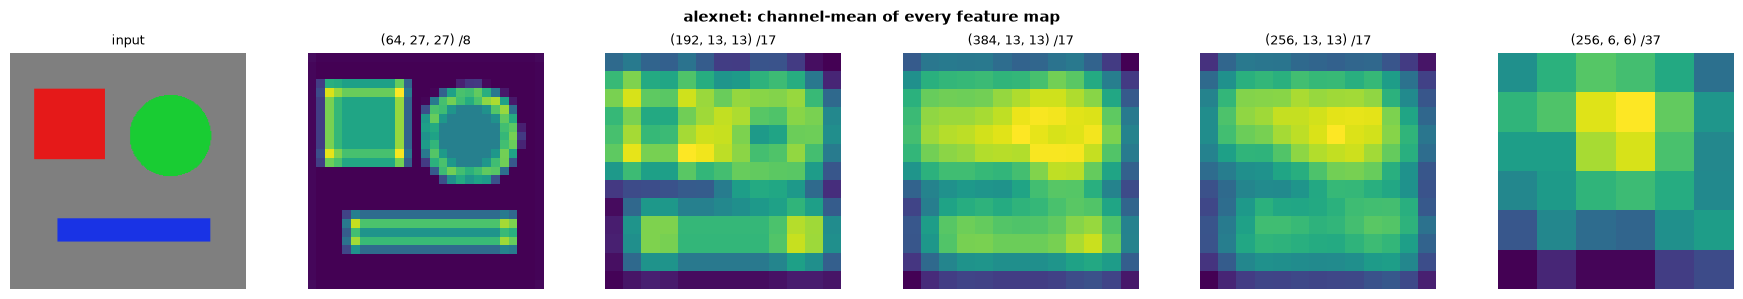

In [11]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [12]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [13]:
import torch
import sys


# Build AlexNet
bb = build_vision_backbone('alexnet', img_size=224)
bb.eval()

x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    out = bb(x)

print(f'pooled_output: {out.pooled_output.shape}')  # [1, 4096]
print(f'patch_tokens:  {out.patch_tokens}')          # None
print(f'feature_maps:')
for i, fm in enumerate(out.feature_maps):
    print(f'  stage {i}: {tuple(fm.shape)}')

print(f'\nParameters: {bb.num_parameters():,}')
print(f'embed_dim:   {bb.embed_dim}')
print(f'feature_dims: {bb.feature_dims}')

pooled_output: torch.Size([1, 4096])
patch_tokens:  None
feature_maps:
  stage 0: (1, 64, 27, 27)
  stage 1: (1, 192, 13, 13)
  stage 2: (1, 384, 13, 13)
  stage 3: (1, 256, 13, 13)
  stage 4: (1, 256, 6, 6)

Parameters: 57,003,840
embed_dim:   4096
feature_dims: [64, 192, 384, 256, 256]


## References

| Paper | Venue | Key Contribution |
|-------|-------|------------------|
| Krizhevsky et al. (2012). ImageNet Classification with Deep CNNs. | NeurIPS 2012 | AlexNet — ReLU, Dropout, GPU training |
| LeCun et al. (1989). Backpropagation to handwritten digit recognition. | Neural Computation | LeNet — Pioneering CNN |
| Simonyan & Zisserman (2015). Very Deep CNNs. | ICLR 2015 | VGGNet — small 3×3 filters, more depth |
| He et al. (2016). Deep Residual Learning. | CVPR 2016 | ResNet — skip connections, 1000+ layers |
| Srivastava et al. (2014). Dropout. | JMLR 2014 | Formal analysis of dropout regularisation |

**Full Citation:**
> Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). ImageNet classification with deep convolutional neural networks. In *Advances in Neural Information Processing Systems* (Vol. 25, pp. 1097–1105). Curran Associates.